In [2]:
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated, Literal



In [19]:
class QuadState(TypedDict):
    a: int
    b: int
    c: int

    equation: str
    discriminant: float
    result:str 
    

In [85]:
def show_equation(state:QuadState):
    """ """
    equation = f"{state['a']} {state['b']}  {state['c']}"

    return {"equation": equation}

def calculate_discriminant(state:QuadState):
    """ """
    # discriminant = state['b']**2 - (4*{state['a']} * {state['c']}) # this line will throug the next Error: TypeError: unsupported operand type(s) for *: 'int' and 'set' # During task with name 'calculate_discriminent' and id 'd385a1a4-c3f9-d871-9413-560fdb2670e1'
    discriminant = state['b']**2 - (4*state['a'] * state['c'])


    return {"discriminant": discriminant}

def real_roots(state: QuadState):
    root1= ((-state['b'] + state['discriminant']**0.5)/(2*state['a']))
    root2= ((-state['b'] - state['discriminant']**0.5))/(2*state['a'])
    result = f"the roots are {root1} and {root2}"
    return {"result": result} 

def repeated_roots(state: QuadState):
    root = (-state['b'])/(2*state['a'])
    result = f"only repeating loop is {root}"
    return {"result": result}

def no_real_roots(state: QuadState):
    result = f"No real roots"
    return {"result": result}

def check_condition(state: QuadState)-> Literal["real_roots", "no_real_roots", "repeated_roots"]:
    if state['discriminant'] > 0:
        return real_roots
    if state['discriminant'] == 0:
        return repeated_roots
    else:
        return no_real_roots

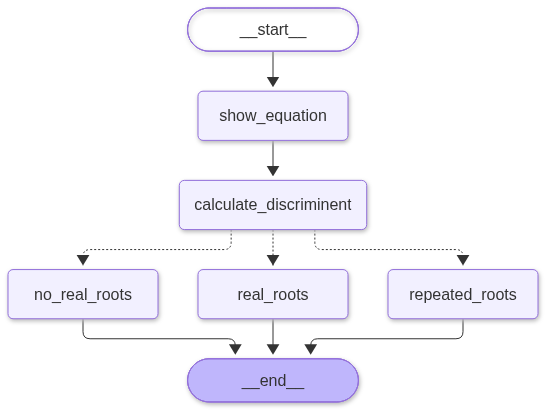

In [87]:
graph = StateGraph(QuadState)

graph.add_node("show_equation", show_equation)
graph.add_node("calculate_discriminent", calculate_discriminant)
graph.add_node("real_roots", real_roots)
graph.add_node("no_real_roots", no_real_roots)
graph.add_node("repeated_roots", repeated_roots)

# graph.add_node("",)
# graph.add_node("",)
# graph.add_node("",)

graph.add_edge(START, "show_equation")
graph.add_edge("show_equation", "calculate_discriminent")

graph.add_conditional_edges('calculate_discriminent', check_condition)

graph.add_edge("real_roots", END)
graph.add_edge("repeated_roots", END)
graph.add_edge("no_real_roots", END)



graph.compile()

In [78]:
workflow = graph.compile()
initial_state = {
    "a":4,
    "b":-5,
    "c":-4,
}

final_state = workflow.invoke(initial_state)
print(final_state)

{'a': 4, 'b': -5, 'c': -4, 'equation': '4 -5  -4', 'discriminant': 89}


# **Extra Practice**

In [59]:
def show_equation(state: QuadState) -> dict:
    # Handle mathematical operators visually (+/- signs handled natively)
    sign_b = "+" if state['b'] >= 0 else ""
    sign_c = "+" if state['c'] >= 0 else ""
    equation = f"{state['a']}x² {sign_b}{state['b']}x {sign_c}{state['c']} = 0"
    print(sign_b)
    return {"equation": equation}
rr = show_equation({
    "a":4,
    "b":-5,
    "c":-4,
})
print(rr)


{'equation': '4x² -5x -4 = 0'}


In [58]:
def show_equation(state: QuadState)-> dict:
    plus = '+'
    minus = '-'
sign = '+'
a = 5
b = -6
print(f"{a}{sign}{b}")
print(f"{a}{sign}{b}")
print(sign)

5+-6
5+-6
+


In [81]:
#value update

a : int
a = 5
a= 9
print(a)

9
